In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# 가우시안 혼합(Gaussian Mixture)

전체 집단 내부에 속한 하위 집단의 존재를 가정한 확률 모델이다.  
전체 집단의 확률 분포가 가우시안 분포를 따르는 경우 정규 분포 가우시안 분포라 부른다. 또한 가우시안 혼합 모델은 비지도 학습의 한 종류로 클러스터링에 사용된다.

## 사이킷런에서 제공하는 데이터를 이용하는 가우시안 혼합 클러스터링 알고리즘을 적용한다.

In [2]:
x_train, y_train = datasets.make_blobs(n_samples=100, n_features=2, centers=6, random_state=23)
print(x_train.shape, y_train.shape)

(100, 2) (100,)


## 가우시안 혼합 클러스터링 적용 전 데이터 시각화

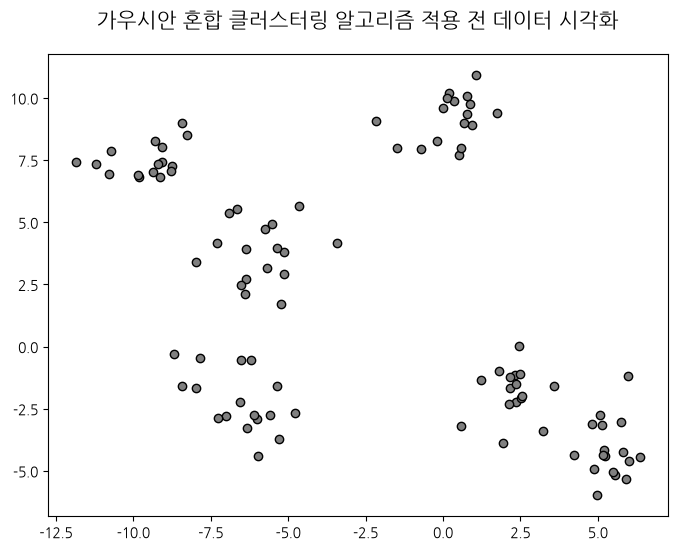

In [3]:
plt.figure(figsize=[8, 6])
plt.scatter(x_train[:, 0], x_train[:, 1], c='gray', edgecolors='black', marker='o')
plt.title('가우시안 혼합 클러스터링 알고리즘 적용 전 데이터 시각화', pad=20, fontsize=15)
plt.show()

## 가우시안 혼합 클러스터링 모델을 만들고 학습 시킨다.

가우시안 혼합 클러스터링 알고리즘을 사용하기 위해 GaussianMixture를 import 한다.

In [4]:
from sklearn.mixture import GaussianMixture

n_components에 군집화하려는 클러스터의 개수를 지정해서 가우시안 혼합 클러스터링 모델을 만들고 군집화할 데이터를 넘겨서 학습시킨다.

In [7]:
model = GaussianMixture(n_components=6, random_state=0)
model.fit(x_train)

GaussianMixture(n_components=6, random_state=0)

## 클러스터링 결과를 확인한다.

fit_predict() 메소드에 피처 데이터를 넘겨서 예측하면 클러스터링과 같은 결과가 나온다.

In [9]:
print(model.fit_predict(x_train))

[2 1 2 5 4 0 0 4 5 4 4 2 4 3 5 3 2 1 1 3 1 5 2 0 0 4 0 0 4 1 1 2 4 5 1 4 2
 5 4 5 2 3 0 3 0 2 3 4 5 5 4 2 0 4 0 1 1 5 3 0 5 1 3 1 4 4 3 0 2 5 1 2 3 3
 1 0 1 4 0 5 5 0 2 2 1 1 3 3 3 0 0 2 3 4 2 5 5 3 2 5]


## 데이터프레임을 만들고 파생 변수를 만들고 각 데이터가 할당된 클러스터를 넣어준다.

In [10]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_blobs() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.fit_predict(x_train) # 가우시안 혼합 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.884120,9.751371,0,2
1,1.944001,-3.858644,4,1
2,-0.001501,9.609392,0,2
3,5.928309,-5.344657,1,5
4,-6.402031,2.126333,2,4
5,-6.206620,-0.533699,3,0
6,-6.003600,-2.896963,3,0
7,-7.302346,4.185701,2,4
8,6.012819,-4.620225,1,5
9,-6.374456,2.712907,2,4


## 가우시안 혼합 클러스터링 적용 후 데이터 시각화

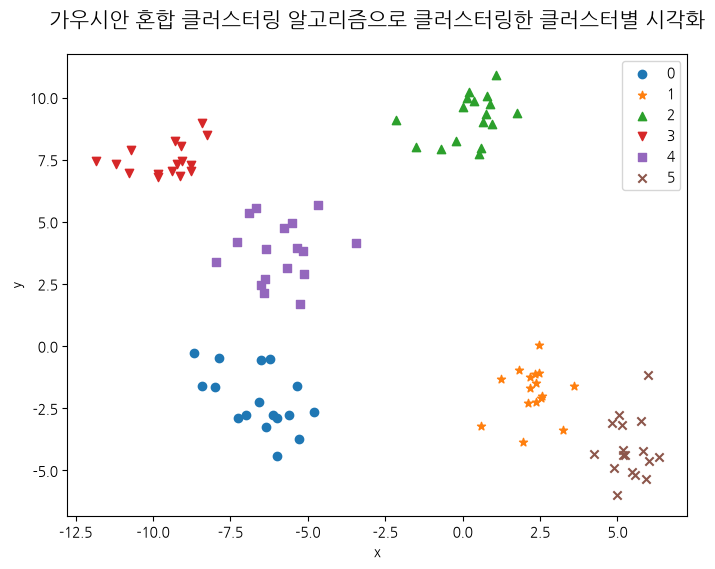

In [12]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('가우시안 혼합 클러스터링 알고리즘으로 클러스터링한 클러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 모델을 평가한다.

In [13]:
score = silhouette_score(x_train, model.fit_predict(x_train))
print(score)

0.6580963691356235
